# Decode & Detect — EDA, feature engineering and fraud scoring

Every transaction gets a suspicion score in [0, 1] from three detectors, then a blend:

| Detector | Type | Role |
|---|---|---|
| **Isolation Forest** | unsupervised | "how unusual is this payment?" — needs no labels, so it can flag motifs the labels never showed |
| **LightGBM** | supervised, tabular | learns which engineered features separate the planted motifs from normal activity |
| **Graph Neural Network** | supervised, graph | edge classifier with message passing over the account graph (pure PyTorch, no PyG needed) |

**Metric:** 100 × average precision (AP), same as the hackathon site. Random ≈ 3 (3.1 % of training transactions are suspicious).

**Leakage rules followed** (from the README): `scenario_id`, `cohort_id`, `family`, `difficulty` are used only for *evaluation and CV grouping*, never as features. Which split a row comes from is never a feature. Features use only transaction/transfer/rate data, so they exist identically in the test set.

**Layout expected next to this notebook:** `train/`, `validation/`, and `test/` from the second download.

In [28]:
import json, math, time, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import sparse
from scipy.sparse.csgraph import connected_components
from sklearn.ensemble import IsolationForest
from sklearn.metrics import average_precision_score
from sklearn.model_selection import StratifiedGroupKFold

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 80)

DATA_DIR  = Path(".")
TRAIN_DIR, VALID_DIR, TEST_DIR = DATA_DIR/"train", DATA_DIR/"validation", DATA_DIR/"test"
SEED, N_FOLDS = 42, 5
RUN_GNN = True            # set False to skip the (slowest) GNN section
OUT_DIR = Path("outputs"); OUT_DIR.mkdir(exist_ok=True)

## 1. Load the data

In [29]:
def read_split(d):
    d = Path(d)
    raw = {n: pd.read_parquet(d/f"{n}.parquet") for n in ["transactions", "transfers", "blocks"]}
    raw["rates"] = pd.read_csv(d/"market_rates.csv")
    return raw

raw_tr = read_split(TRAIN_DIR)
labels = pd.read_csv(TRAIN_DIR/"labels.csv")
for name in ["transactions", "transfers", "blocks"]:
    df = raw_tr[name]
    print(f"── {name}: {df.shape[0]:,} rows × {df.shape[1]} cols")
    print(df.dtypes.to_string(), "\n")
raw_tr["transactions"].head(3).T

── transactions: 40,131 rows × 26 cols
LEDGER_INDEX                             object
TIMESTAMP                                object
DATETIME                    datetime64[ms, UTC]
LEDGER_HASH                                 str
TRANSACTION_HASH                            str
TRANSACTION_INDEX                        object
ACCOUNT                                     str
TRANSACTION_TYPE                            str
SOURCE_FEE                               object
FEE                                     float64
SEQUENCE                                 object
ACCOUNT_TRANSACTION_ID                      str
FLAGS                                    object
LAST_LEDGER_SEQUENCE                     object
MEMOS                                       str
SIGNERS                                     str
SOURCE_TAG                               object
SIGNING_PUB_KEY                             str
TICKET_SEQUENCE                          object
TXN_SIGNATURE                               str
T

,0,1,2
LEDGER_INDEX,1124529,1136375,1129067
TIMESTAMP,1788718916,1788766300,1788737068
DATETIME,2026-09-06 18:21:56+00:00,2026-09-07 07:31:40+00:00,2026-09-06 23:24:28+00:00
LEDGER_HASH,6F7094E1DDA27405855AB2CE4E97A555E0B372D45625B3...,6760D562E18F762A5068E23BAC9CDE21AE43D11C44E466...,FCBE03345724C312C98168B9F2C4C0FA2B2A181B6FBFA3...
TRANSACTION_HASH,954736A6E1BB5A3433EB916D8221F2DF5938A521EA2222...,C93CF387C2148608329ED89420105EFD883020CDBFDFAE...,E46BFC5EC409B486E1C97F20BCB62AE96432B20937D265...
TRANSACTION_INDEX,0,1,1
ACCOUNT,r3CWFt1SXiykW92LwKU19CvfTFcFRnbnDY,rEFG2WG1W8bHQhHp2P1rcxRBMxmz9C52B7,rJxqpGRZ2bJtB1Q8HYCV9iPon9HpvJugZm
TRANSACTION_TYPE,Payment,Payment,Payment
SOURCE_FEE,10,15,15
FEE,0.00001,0.000015,0.000015


### Build one row per payment

The README's key points that shape this step:

* one **customer edge** per transaction: `ACCOUNT → Destination` (inside `EXTRA_TRANSACTION_FIELDS`), delivering `DELIVERED_AMOUNT`;
* assets are only comparable after valuing them with the hourly reference price of **that exact asset** (issuer matters);
* `SendMax` is a ceiling, **not** the real cost — the real cost is the **first executed transfer leg**;
* 1–3 transfer legs per transaction (1 = direct, 2 = direct conversion, 3 = XRP bridge).

In [30]:
def parse_obj(w):
    """XRPL amount -> (asset key, units). XRP: string of drops. IOU: {currency, issuer, value}."""
    if isinstance(w, (str, int)):
        return "XRP", int(w) / 1e6
    return f"{w['issuer']}:{w['currency']}", float(w["value"])

def to_usd(price, t, asset, units):
    key = pd.MultiIndex.from_arrays([(t // 3600 * 3600).to_numpy(), pd.Series(asset).to_numpy()])
    return units.to_numpy() * price.reindex(key).to_numpy()

def build_payments(raw):
    tx = raw["transactions"].reset_index(drop=True)
    rates = raw["rates"]
    price = (rates.assign(hour=rates.TIMESTAMP.astype("int64"), price=rates.PRICE_MICRO_USD / 1e6)
                  .set_index(["hour", "ASSET"]).price)
    extra = [json.loads(x) for x in tx.EXTRA_TRANSACTION_FIELDS]
    dlv = [parse_obj(json.loads(x)) for x in tx.DELIVERED_AMOUNT]
    sm = [parse_obj(e["SendMax"]) if e.get("SendMax") is not None else (None, np.nan) for e in extra]
    fee_col = next((c for c in ["FEE", "TRANSACTION_FEE", "FEE_DROPS"] if c in tx.columns), None)

    pay = pd.DataFrame({
        "TRANSACTION_HASH": tx.TRANSACTION_HASH,
        "t": tx.TIMESTAMP.astype("int64"),
        "sender": tx.ACCOUNT,
        "receiver": [e["Destination"] for e in extra],
        "dst_asset": [a for a, _ in dlv], "dst_units": [u for _, u in dlv],
        "sendmax_asset": [a for a, _ in sm], "sendmax_units": [u for _, u in sm],
        "fee": pd.to_numeric(tx[fee_col], errors="coerce") if fee_col else np.nan,
    })

    # executed legs: actual cost = first leg
    tr = raw["transfers"][["TRANSACTION_HASH", "TRANSFER_INDEX", "TRANSFER_TYPE", "SYMBOL",
                           "TOKEN_ADDRESS", "VALUE"]].sort_values(["TRANSACTION_HASH", "TRANSFER_INDEX"])
    tr["asset"] = np.where(tr.SYMBOL.eq("XRP"), "XRP", tr.TOKEN_ADDRESS.astype(str) + ":" + tr.SYMBOL.astype(str))
    tr["is_path"] = tr.TRANSFER_TYPE.eq("path_payment")
    g = tr.groupby("TRANSACTION_HASH", sort=False)
    legs = pd.DataFrame({"n_legs": g.size(), "is_path": g.is_path.max(),
                         "src_asset": g.asset.first(), "src_units": g.VALUE.first().astype(float)})
    pay = pay.merge(legs, left_on="TRANSACTION_HASH", right_index=True, how="left").reset_index(drop=True)

    pay["dst_usd"] = to_usd(price, pay.t, pay.dst_asset, pay.dst_units)
    pay["src_usd"] = to_usd(price, pay.t, pay.src_asset, pay.src_units)
    pay["sendmax_usd"] = to_usd(price, pay.t, pay.sendmax_asset, pay.sendmax_units)
    return pay.sort_values("t", kind="stable").reset_index(drop=True)

pay_tr = build_payments(raw_tr)
assert pay_tr.TRANSACTION_HASH.is_unique and set(pay_tr.TRANSACTION_HASH) == set(labels.TRANSACTION_HASH)
print(f"{len(pay_tr):,} payments · USD-valuation missing for {pay_tr.dst_usd.isna().sum()} · "
      f"legs missing for {pay_tr.n_legs.isna().sum()}")
pay_tr.head()

40,131 payments · USD-valuation missing for 0 · legs missing for 0


,TRANSACTION_HASH,t,sender,receiver,dst_asset,dst_units,sendmax_asset,sendmax_units,fee,n_legs,is_path,src_asset,src_units,dst_usd,src_usd,sendmax_usd
0,4A62FF3CE01C3F3F88F7845CBD092C802BE316BF9A7445...,1788221144,rPBdsuMzaspzpExwEQgxLLmQZkLP7ESX3N,rnAVLU3WJsLtwzxZ6mcZJV1egzVkKFc3fU,r99vy4o5fXhC3PwEXEpnc1f9Mss4aCzYBW:USD,25.613174,NaN,NaN,0.000015,1,False,r99vy4o5fXhC3PwEXEpnc1f9Mss4aCzYBW:USD,25.613174,25.662454,25.662454,NaN
1,1C4EB7EEAE2D6E1C7712BA3DF63C5DF50F6C6C77A1C6DB...,1788221284,rKWLvQB2U3XY4JkQExifZi796XkEidsPWH,rD213k4eGiT5GcktVk3fDECDMUHxGKFTu4,rLeMq5iFyEhgHLfBxeu4eRQWEGGdeL8hXK:USD,6.412834,NaN,NaN,0.000015,1,False,rLeMq5iFyEhgHLfBxeu4eRQWEGGdeL8hXK:USD,6.412834,6.408499,6.408499,NaN
2,7F44D6D68CEAE7BB61CE9AA13EB2947BE67F00D09321AA...,1788221300,rQawrHKf1KqgZrG2By3crBZaMo5HJ8z8az,rHGshnkdCkBiPpSsmwoggof25Lf7CeJkwx,rLeMq5iFyEhgHLfBxeu4eRQWEGGdeL8hXK:USD,11.323993,XRP,17.633592,0.000015,2,True,XRP,17.459001,11.316338,11.368394,11.482078
3,EA661691712B55D2D9B161FDA3D02FC9BFDA5D691DCE74...,1788221896,r4aYF3B624kQQ1PuRScBAYmpi8UoVug34H,rMJgaQr4Dzfsq5tHTG4Fukt9Ym6jDs9H2Y,rLeMq5iFyEhgHLfBxeu4eRQWEGGdeL8hXK:USD,172.268685,NaN,NaN,0.000012,1,False,rLeMq5iFyEhgHLfBxeu4eRQWEGGdeL8hXK:USD,172.268685,172.152231,172.152231,NaN
4,B5942729703DD6BE94201C723512EF61914F05571476C3...,1788222036,rhqpZBg5dRRghdaZXMA9Yz1Jz64Z7LrtyQ,rwVGfwAWEo6wS3yAzbJdb1VocrV1i5C6ZU,r99vy4o5fXhC3PwEXEpnc1f9Mss4aCzYBW:USD,11.327982,r99vy4o5fXhC3PwEXEpnc1f9Mss4aCzYBW:GBP,8.855756,0.000015,2,True,r99vy4o5fXhC3PwEXEpnc1f9Mss4aCzYBW:GBP,8.768075,11.349777,11.379287,11.493080


## 2. Exploratory data analysis
### 2.1 Labels: what we are hunting

In [31]:
meta = labels.set_index("TRANSACTION_HASH")
tab = (labels.groupby(["family", "difficulty"]).is_suspicious
             .agg(transactions="size", suspicious="sum").reset_index())
print(f"{len(labels):,} transactions · {labels.is_suspicious.sum():,} suspicious "
      f"({labels.is_suspicious.mean():.2%}) · {labels.scenario_id.nunique():,} planted scenarios")
tab

40,131 transactions · 1,250 suspicious (3.11%) · 1,497 planted scenarios


,family,difficulty,transactions,suspicious
0,aggregate_relay,hard,102,102
1,aggregate_relay,normal,10098,0
2,ambiguous,hard,25,25
3,background,normal,18000,0
4,bipartite,easy,113,113
5,bipartite,medium,21,21
6,bipartite,normal,152,0
7,chain,easy,63,63
8,chain,medium,10,10
9,chain,normal,66,0


**Things worth noticing in that table** (these drive the design choices below):

* *Easy/medium* families (fan-in, fan-out, cycle, chain, stack, bipartite, multi-stage, random…) each come with a similar number of **lookalike normal** payments — so a single "burstiness" rule is not enough.
* The two **hard** families (`aggregate_relay`, `distributed_relay`) are ~100 positives hidden among ~10 000 normal relay-like payments each. They only show up in **aggregate flows over longer windows**, so the features include 10 min → 24 h → whole-week inflow/outflow windows.
* The `ambiguous` family (25 rows) is, per the README, *independent of observable features* — nothing can score those above chance. They cap the achievable AP.

### 2.2 Assets, prices and time

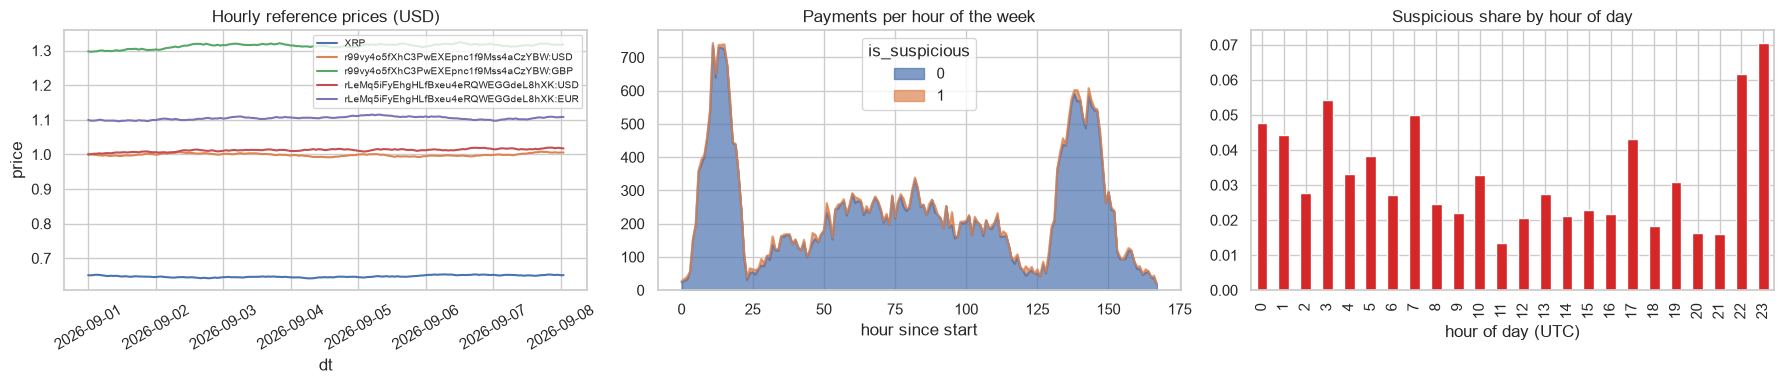

In [32]:
rates = raw_tr["rates"].copy()
rates["dt"] = pd.to_datetime(rates.TIMESTAMP, unit="s")
rates["price"] = rates.PRICE_MICRO_USD / 1e6
fig, ax = plt.subplots(1, 3, figsize=(18, 4))
sns.lineplot(data=rates, x="dt", y="price", hue="ASSET", ax=ax[0]); ax[0].set_title("Hourly reference prices (USD)")
ax[0].legend(fontsize=7); ax[0].tick_params(axis="x", rotation=30)

p = pay_tr.merge(labels[["TRANSACTION_HASH", "is_suspicious", "family", "difficulty"]], on="TRANSACTION_HASH")
hours = (p.t - p.t.min()) // 3600
p.groupby([hours, "is_suspicious"]).size().unstack(fill_value=0).plot.area(ax=ax[1], alpha=.7)
ax[1].set_title("Payments per hour of the week"); ax[1].set_xlabel("hour since start")

p.groupby((p.t % 86400) // 3600).is_suspicious.mean().plot.bar(ax=ax[2], color="tab:red")
ax[2].set_title("Suspicious share by hour of day"); ax[2].set_xlabel("hour of day (UTC)")
plt.tight_layout(); plt.show()

### 2.3 Payment-level behaviour: value, route, cost

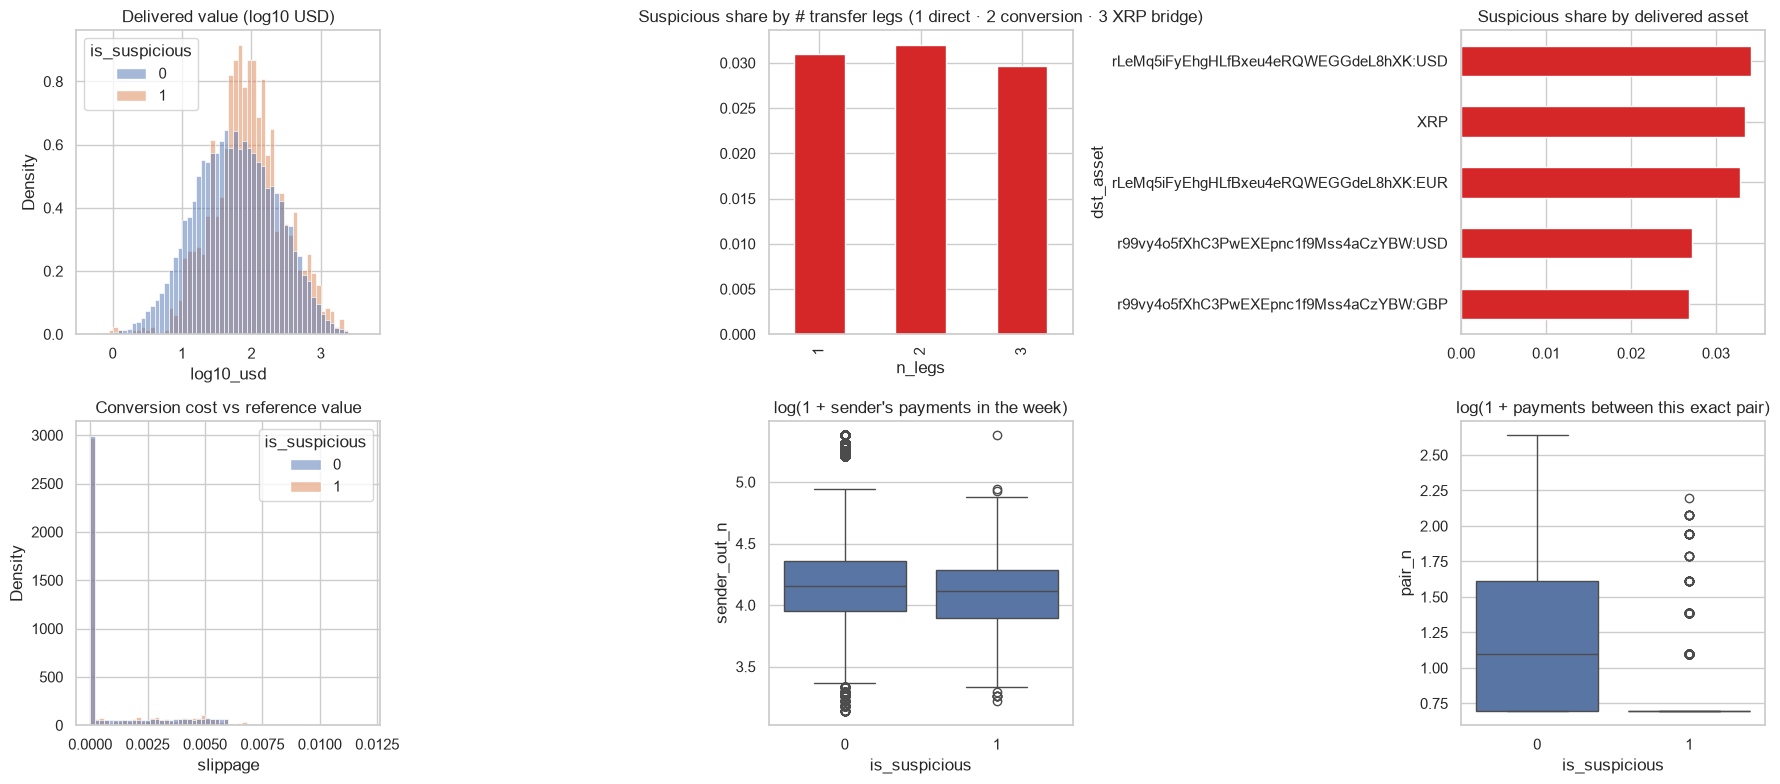

Suspicious share by family × conversion:


conversion,False,True
family,,
aggregate_relay,0.010,0.010
ambiguous,1.000,1.000
background,0.000,0.000
bipartite,0.382,0.587
chain,0.583,0.436
cycle,0.464,0.329
distributed_relay,0.010,0.009
fan_in,0.564,0.579
fan_out,0.515,0.609


In [33]:
p["log10_usd"] = np.log10(p.dst_usd.clip(lower=1e-6))
p["slippage"] = (p.src_usd / p.dst_usd - 1).replace([np.inf, -np.inf], np.nan)
p["conversion"] = p.src_asset != p.dst_asset
p["sender_out_n"] = p.sender.map(p.sender.value_counts())
p["pair_n"] = p.groupby(["sender", "receiver"]).TRANSACTION_HASH.transform("size")

fig, ax = plt.subplots(2, 3, figsize=(18, 8))
sns.histplot(data=p, x="log10_usd", hue="is_suspicious", stat="density", common_norm=False, bins=60, ax=ax[0, 0])
ax[0, 0].set_title("Delivered value (log10 USD)")
p.groupby("n_legs").is_suspicious.agg(["mean", "size"]).assign(share=lambda d: d["mean"]).share.plot.bar(ax=ax[0, 1], color="tab:red")
ax[0, 1].set_title("Suspicious share by # transfer legs (1 direct · 2 conversion · 3 XRP bridge)")
p.groupby("dst_asset").is_suspicious.mean().sort_values().plot.barh(ax=ax[0, 2], color="tab:red")
ax[0, 2].set_title("Suspicious share by delivered asset")
sns.histplot(data=p[p.slippage.between(-.1, .2)], x="slippage", hue="is_suspicious", stat="density",
             common_norm=False, bins=60, ax=ax[1, 0]); ax[1, 0].set_title("Conversion cost vs reference value")
sns.boxplot(data=p, x="is_suspicious", y=np.log1p(p.sender_out_n), ax=ax[1, 1]); ax[1, 1].set_title("log(1 + sender's payments in the week)")
sns.boxplot(data=p, x="is_suspicious", y=np.log1p(p.pair_n), ax=ax[1, 2]); ax[1, 2].set_title("log(1 + payments between this exact pair)")
plt.tight_layout(); plt.show()

print("Suspicious share by family × conversion:")
p.pivot_table(index="family", columns="conversion", values="is_suspicious", aggfunc="mean").round(3)

### 2.4 The account graph

700 accounts · 22,315 distinct sender→receiver pairs · 36.3% of pairs pay more than once (recurring relationships)


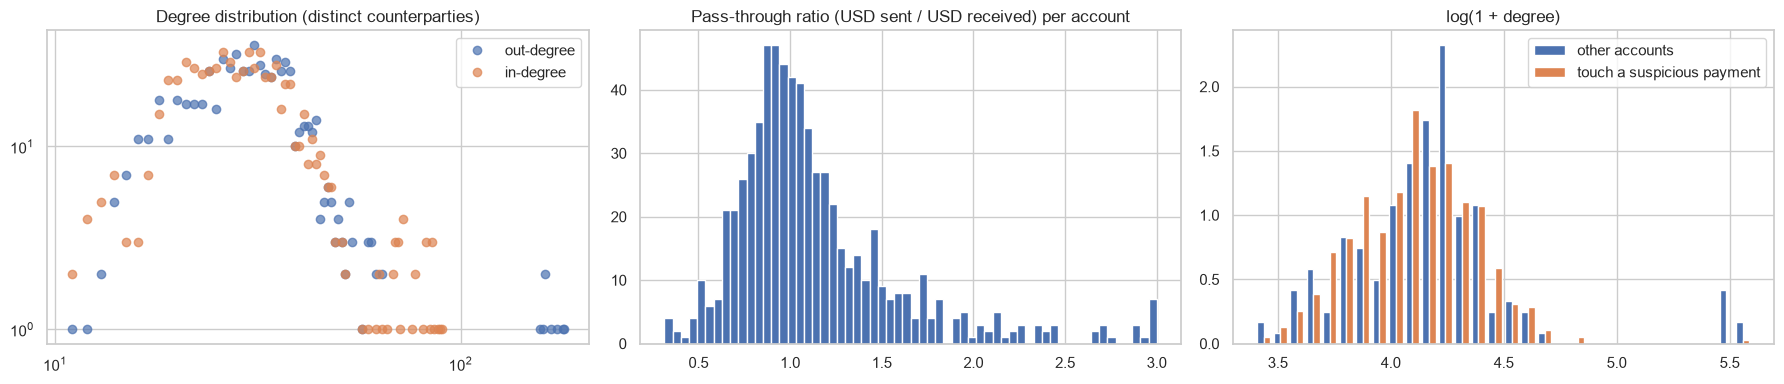

In [34]:
G = pay_tr.groupby(["sender", "receiver"]).size().rename("n").reset_index()
out_deg = G.groupby("sender").receiver.nunique(); in_deg = G.groupby("receiver").sender.nunique()
accounts = pd.Index(pd.concat([pay_tr.sender, pay_tr.receiver]).unique())
print(f"{len(accounts):,} accounts · {len(G):,} distinct sender→receiver pairs · "
      f"{(G.n > 1).mean():.1%} of pairs pay more than once (recurring relationships)")

fig, ax = plt.subplots(1, 3, figsize=(18, 4))
for s, lab in [(out_deg, "out"), (in_deg, "in")]:
    vc = s.value_counts().sort_index(); ax[0].loglog(vc.index, vc.values, "o", label=f"{lab}-degree", alpha=.7)
ax[0].set_title("Degree distribution (distinct counterparties)"); ax[0].legend()

sent = pay_tr.groupby("sender").dst_usd.sum(); got = pay_tr.groupby("receiver").dst_usd.sum()
pt = (sent / got.reindex(sent.index)).replace([np.inf], np.nan).dropna().clip(0, 3)
ax[1].hist(pt, bins=60); ax[1].set_title("Pass-through ratio (USD sent / USD received) per account")

susp_acc = pd.concat([p[p.is_suspicious == 1].sender, p[p.is_suspicious == 1].receiver]).unique()
deg_all = (out_deg.reindex(accounts).fillna(0) + in_deg.reindex(accounts).fillna(0))
ax[2].hist([np.log1p(deg_all[~deg_all.index.isin(susp_acc)]), np.log1p(deg_all[deg_all.index.isin(susp_acc)])],
           bins=30, density=True, label=["other accounts", "touch a suspicious payment"])
ax[2].legend(); ax[2].set_title("log(1 + degree)"); plt.tight_layout(); plt.show()

## 3. Feature engineering

~100 features in six groups. Every feature is computed **within one split only** (a split is a self-contained week with disjoint wallets) and uses no labels.

| Group | Examples | Targets which motif |
|---|---|---|
| Payment | value, round amounts, hour, route (direct / conversion / XRP bridge), asset one-hot, conversion slippage vs reference price, SendMax ratio, fee | `random`, `stack` (round / repeated amounts) |
| Account profile | sender/receiver counts, unique counterparties, USD in/out, mean/std/max, pass-through ratio, counterparty diversity | relays, mules, hubs |
| Pair history | times this pair paid before, gap since last payment, reciprocal payments, same-amount repeats | recurring commerce vs one-off |
| Time windows (10 m · 1 h · 6 h · 24 h · week) | sender/receiver burst counts; **receiver forwards X % of this amount onward**; **sender was funded by X % of this amount just before**; gaps to next send / previous receipt | `fan_in`, `fan_out`, `chain`, `multi_stage`, `*_relay` |
| Graph structure | directed cycles back to the sender (2- and 3-hop), 2-hop path counts, PageRank, component size, neighbour degree | `cycle`, `bipartite`, `fan_out_in` |

Window queries are done in a vectorised way: events are sorted by `(account, time)`, and each window is two binary searches on a prefix-sum array.

In [35]:
BIG = np.int64(10 ** 10)          # > max timestamp, so (account, time) packs into one sortable int64
WEEK = 8 * 86400
ASSETS = sorted(raw_tr["rates"].ASSET.unique())

class Events:
    """Per-account time-ordered events with prefix sums: any window total/count = 2 binary searches."""
    def __init__(self, codes, t, v):
        order = np.lexsort((t, codes))
        self.key = codes[order].astype(np.int64) * BIG + t[order].astype(np.int64)
        self.cum = np.concatenate([[0.0], np.cumsum(v[order])])
    def _ij(self, codes, t, lo, hi):
        base = codes.astype(np.int64) * BIG + t.astype(np.int64)
        return np.searchsorted(self.key, base + lo, "left"), np.searchsorted(self.key, base + hi, "right")
    def count(self, codes, t, lo, hi):
        i, j = self._ij(codes, t, lo, hi); return (j - i).astype(float)
    def total(self, codes, t, lo, hi):
        i, j = self._ij(codes, t, lo, hi); return self.cum[j] - self.cum[i]
    def next_gap(self, codes, t, cap):
        base = codes.astype(np.int64) * BIG + t.astype(np.int64)
        i = np.searchsorted(self.key, base + 1, "left"); ok = i < len(self.key)
        nxt = self.key[np.minimum(i, len(self.key) - 1)]
        return np.minimum(np.where(ok & (nxt // BIG == codes), nxt - base, cap), cap).astype(float)
    def prev_gap(self, codes, t, cap):
        base = codes.astype(np.int64) * BIG + t.astype(np.int64)
        i = np.searchsorted(self.key, base, "left") - 1; ok = i >= 0
        prv = self.key[np.maximum(i, 0)]
        return np.minimum(np.where(ok & (prv // BIG == codes), base - prv, cap), cap).astype(float)

def _role_stats(codes, other, usd, p):
    g = pd.DataFrame({"c": codes, "o": other, "u": usd}).groupby("c")
    return pd.DataFrame({f"{p}_n": g.size(), f"{p}_uniq": g.o.nunique(), f"{p}_sum": g.u.sum(),
                         f"{p}_mean": g.u.mean(), f"{p}_std": g.u.std(), f"{p}_max": g.u.max()})

def _safe_div(a, b): return np.divide(a, b, out=np.full(len(a), np.nan), where=np.asarray(b) > 0)

In [36]:
def make_features(pay):
    """pay -> dict(X=tx features, s/r=account codes per tx, nodes=account table, N=#accounts). Label-free."""
    pay = pay.sort_values("t", kind="stable").reset_index(drop=True)
    n = len(pay)
    codes, _ = pd.factorize(pd.concat([pay.sender, pay.receiver], ignore_index=True))
    s, r, N = codes[:n], codes[n:], codes.max() + 1
    t = pay.t.to_numpy(); usd = pay.dst_usd.fillna(0).to_numpy(); units = pay.dst_units.to_numpy()
    f = pd.DataFrame(index=pay.index)

    # ── payment-level ─────────────────────────────────────────────────────
    f["log_usd"] = np.log1p(usd)
    f["log_units"] = np.log1p(units)
    f["hour"] = (t % 86400) / 3600
    f["round_usd_100"] = (usd % 100 < 0.5).astype(float)
    f["round_units_1"] = (np.abs(units - np.round(units)) < 1e-6).astype(float)
    f["round_units_100"] = ((np.abs(units - np.round(units)) < 1e-6) & (np.round(units) % 100 == 0)).astype(float)
    f["n_legs"] = pay.n_legs.to_numpy(float)
    f["is_path"] = pay.is_path.astype(float).to_numpy()
    f["is_conversion"] = (pay.src_asset != pay.dst_asset).astype(float).to_numpy()
    for a in ASSETS:
        k = a.split(":")[-1][:3] + ("_" + a[1:4] if ":" in a else "")
        f[f"dst_{k}"] = (pay.dst_asset == a).astype(float).to_numpy()
        f[f"src_{k}"] = (pay.src_asset == a).astype(float).to_numpy()
    f["log_src_usd"] = np.log1p(pay.src_usd.fillna(0).to_numpy())
    f["slippage"] = (pay.src_usd / pay.dst_usd - 1).replace([np.inf, -np.inf], np.nan).to_numpy()
    f["sendmax_ratio"] = (pay.src_usd / pay.sendmax_usd).replace([np.inf, -np.inf], np.nan).to_numpy()
    f["fee"] = pay.fee.to_numpy(float)

    # ── account profile (computed once per account, mapped back to each end of the payment) ──
    A = _role_stats(s, r, usd, "out").join(_role_stats(r, s, usd, "in"), how="outer").reindex(range(N)).fillna(0)
    A["pass_through"] = (A.out_sum / (A.in_sum + 1)).clip(0, 5)
    A["net_flow"] = np.sign(A.in_sum - A.out_sum) * np.log1p((A.in_sum - A.out_sum).abs())
    A["out_share"] = A.out_n / (A.out_n + A.in_n).clip(lower=1)
    A["out_cp_ratio"] = A.out_uniq / A.out_n.clip(lower=1)          # 1 = always a new counterparty
    A["in_cp_ratio"] = A.in_uniq / A.in_n.clip(lower=1)
    ev = pd.DataFrame({"c": np.r_[s, r], "t": np.r_[t, t]}).groupby("c").t
    A["first_t"] = (ev.min().reindex(range(N)) - t.min()) / 3600
    A["span_h"] = (ev.max() - ev.min()).reindex(range(N)).fillna(0) / 3600

    # ── graph structure ───────────────────────────────────────────────────
    Ab = sparse.csr_matrix((np.ones(n), (s, r)), shape=(N, N)); Ab.sum_duplicates(); Ab.data[:] = 1
    AbT = Ab.T.tocsr()
    A["paths2_out"] = Ab @ (Ab @ np.ones(N)); A["paths2_in"] = AbT @ (AbT @ np.ones(N))
    A["nbr_out_deg"] = (Ab @ A.out_uniq.to_numpy()) / A.out_uniq.clip(lower=1)
    A["nbr_in_deg"] = (AbT @ A.in_uniq.to_numpy()) / A.in_uniq.clip(lower=1)
    _, comp = connected_components(Ab, directed=False); A["component_size"] = np.bincount(comp)[comp]
    W = sparse.csr_matrix((usd, (s, r)), shape=(N, N)); W.sum_duplicates()
    rs = np.asarray(W.sum(1)).ravel(); P = sparse.diags(np.divide(1, rs, out=np.zeros(N), where=rs > 0)) @ W
    pr = np.full(N, 1 / N)
    for _ in range(30): pr = 0.15 / N + 0.85 * (P.T @ pr + pr[rs == 0].sum() / N)
    A["pagerank_x1e4"] = pr * 1e4

    for c in A.columns:
        f[f"s_{c}"] = A[c].to_numpy()[s]; f[f"r_{c}"] = A[c].to_numpy()[r]
    f["cyc2"] = np.asarray(Ab[r, s]).ravel()                                   # r pays s back directly
    f["cyc3"] = np.asarray(Ab[r].multiply(AbT[s]).sum(1)).ravel()              # r -> x -> s
    f["usd_vs_sender_mean"] = np.log1p(usd) - np.log1p(f.s_out_mean)
    f["usd_vs_receiver_in_mean"] = np.log1p(usd) - np.log1p(f.r_in_mean)
    f["share_of_sender_out"] = _safe_div(usd, f.s_out_sum.to_numpy())
    f["share_of_receiver_in"] = _safe_div(usd, f.r_in_sum.to_numpy())

    # ── pair history ──────────────────────────────────────────────────────
    pair = pd.Series(s.astype(np.int64) * N + r); rev = pd.Series(r.astype(np.int64) * N + s)
    pg = pair.groupby(pair)
    f["pair_n"] = pg.transform("size").to_numpy(float)
    f["pair_rank"] = pg.cumcount().to_numpy(float)
    f["pair_first"] = (f.pair_rank == 0).astype(float)
    f["pair_total_log"] = np.log1p(pd.Series(usd).groupby(pair).transform("sum").to_numpy())
    f["rev_pair_n"] = rev.map(pair.value_counts()).fillna(0).to_numpy(float)
    f["pair_share_of_sender_out"] = f.pair_n / f.s_out_n.clip(lower=1)
    tt = pd.Series(t, dtype="float64")
    f["pair_gap_prev_h"] = ((tt - tt.groupby(pair).shift(1)) / 3600).to_numpy()
    f["pair_gap_next_h"] = ((tt.groupby(pair).shift(-1) - tt) / 3600).to_numpy()
    same = pd.DataFrame({"s": s, "a": pay.dst_asset, "u": pay.dst_units.round(2), "one": 1})
    f["same_amount_sender"] = same.groupby(["s", "a", "u"]).one.transform("sum").to_numpy(float)
    same2 = pd.DataFrame({"r": r, "a": pay.dst_asset, "u": pay.dst_units.round(2), "one": 1})
    f["same_amount_receiver"] = same2.groupby(["r", "a", "u"]).one.transform("sum").to_numpy(float)

    # ── time windows ──────────────────────────────────────────────────────
    out_ev, in_ev = Events(s, t, usd), Events(r, t, usd)
    eps = 1e-9
    for name, w in {"10m": 600, "1h": 3600, "6h": 21600, "24h": 86400, "wk": WEEK}.items():
        f[f"s_burst_{name}"] = out_ev.count(s, t, -w, w) - 1                  # sender's other payments around t
        f[f"r_burst_{name}"] = in_ev.count(r, t, -w, w) - 1                   # receiver's other receipts around t
        f[f"r_fwd_cnt_{name}"] = out_ev.count(r, t, 0, w)                     # receiver pays onward after t
        f[f"r_fwd_ratio_{name}"] = np.clip(out_ev.total(r, t, 0, w) / (usd + eps), 0, 100)
        f[f"s_funded_cnt_{name}"] = in_ev.count(s, t, -w, 0)                  # sender was paid just before t
        f[f"s_funded_ratio_{name}"] = np.clip(in_ev.total(s, t, -w, 0) / (usd + eps), 0, 100)
    for w in (3600, 86400):
        f[f"r_fwd_dev_{w//3600}h"] = np.abs(f[f"r_fwd_ratio_{'1h' if w == 3600 else '24h'}"] - 1)
        f[f"s_funded_dev_{w//3600}h"] = np.abs(f[f"s_funded_ratio_{'1h' if w == 3600 else '24h'}"] - 1)
    f["r_gap_next_send_min"] = out_ev.next_gap(r, t, 7 * 86400) / 60
    f["s_gap_prev_recv_min"] = in_ev.prev_gap(s, t, 7 * 86400) / 60
    f["s_gap_prev_send_min"] = out_ev.prev_gap(s, t, 7 * 86400) / 60
    f["r_gap_next_recv_min"] = in_ev.next_gap(r, t, 7 * 86400) / 60
    # whole-week cumulative flows around t: long-horizon relay signal (aggregate/distributed relays)
    for who, c in (("s", s), ("r", r)):
        f[f"{who}_in_before"] = np.log1p(in_ev.total(c, t, -WEEK, -1)); f[f"{who}_out_before"] = np.log1p(out_ev.total(c, t, -WEEK, -1))
        f[f"{who}_in_after"] = np.log1p(in_ev.total(c, t, 1, WEEK));  f[f"{who}_out_after"] = np.log1p(out_ev.total(c, t, 1, WEEK))
    f["r_relay_share"] = np.clip(out_ev.total(r, t, 0, WEEK) / (in_ev.total(r, t, -WEEK, 0) + eps), 0, 5)
    f["s_relay_share"] = np.clip(out_ev.total(s, t, 0, WEEK) / (in_ev.total(s, t, -WEEK, 0) + eps), 0, 5)

    X = f.replace([np.inf, -np.inf], np.nan).astype(float)
    X.index = pay.TRANSACTION_HASH.to_numpy()
    nodes = A.copy()
    return dict(X=X, s=s, r=r, N=N, nodes=nodes, pay=pay)

t0 = time.time(); F_tr = make_features(pay_tr)
print(f"{F_tr['X'].shape[1]} features × {len(F_tr['X']):,} payments in {time.time()-t0:.0f}s")

137 features × 40,131 payments in 0s


### 3.1 Which features carry signal on their own?

Univariate average precision of each feature (taking the better of `x` and `−x`), with the random baseline (the base rate) for reference.

In [ ]:
X_tr = F_tr["X"]
lab = meta.loc[X_tr.index]
y = lab.is_suspicious.to_numpy().astype(int)

def uni_ap(x, y):
    x = x.fillna(x.median()).fillna(0).to_numpy()
    return max(average_precision_score(y, x), average_precision_score(y, -x))
ap1 = X_tr.apply(lambda c: uni_ap(c, y)).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(9, 9))
ap1.head(30)[::-1].plot.barh(ax=ax, color="tab:blue"); ax.axvline(y.mean(), color="red", ls="--", label=f"base rate {y.mean():.3f}")
ax.set_title("Top 30 features by univariate AP"); ax.legend(); plt.tight_layout(); plt.show()

In [ ]:
top = list(ap1.index[:6])
fig, ax = plt.subplots(2, 3, figsize=(18, 7))
for a, c in zip(ax.ravel(), top):
    v = X_tr[c].clip(X_tr[c].quantile(.01), X_tr[c].quantile(.99))
    sns.violinplot(x=y, y=v, ax=a, cut=0, inner="quartile"); a.set_title(c); a.set_xlabel("is_suspicious")
plt.tight_layout(); plt.show()

# how well can the *best single feature* find each family?  (share of that family's positives in the top-K, K = #positives)
best = X_tr[ap1.index[0]].fillna(0).to_numpy(); best = best if average_precision_score(y, best) >= average_precision_score(y, -best) else -best
order = pd.Series(best, index=X_tr.index).rank(ascending=False)
rows = []
for fam, d in lab[lab.is_suspicious == 1].groupby("family"):
    rows.append((fam, len(d), (order.loc[d.index] <= y.sum()).mean()))
pd.DataFrame(rows, columns=["family", "positives", f"recall@K using {ap1.index[0]}"]).round(2)

## 4. Evaluation protocol

* **Folds:** `StratifiedGroupKFold`. Positives share a `scenario_id` (a planted motif spans several payments), and wallets are disjoint between the real train/test splits, so groups are `scenario_id` for positives and the **sender wallet** for everything else. A model therefore never sees part of a scenario or a sender in both its fit and check sets.
* **Reported:** AP (= site score / 100), precision and recall in the top 1 % (the site's review budget), and AP restricted to each difficulty tier (positives of that tier + all normal rows).
* All three models produce **out-of-fold (OOF)** scores on `train/`, so they can be compared and blended honestly.

In [ ]:
groups = np.where(lab.scenario_id.notna(), "sc:" + lab.scenario_id.astype(str), "w:" + pay_tr.set_index("TRANSACTION_HASH").sender.loc[X_tr.index].astype(str).to_numpy())
folds = list(StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED).split(X_tr, y, groups))
print("positives per fold:", [int(y[v].sum()) for _, v in folds])

def rank01(x):
    x = pd.Series(np.asarray(x, float)); return x.rank(method="average").sub(1).div(max(len(x) - 1, 1)).to_numpy()

def report(name, score, y=y, lab=lab):
    k = max(int(round(.01 * len(y))), 1); top = np.argsort(-score, kind="stable")[:k]
    out = {"model": name, "AP×100": 100 * average_precision_score(y, score),
           "P@1%": y[top].mean(), "R@1%": y[top].sum() / y.sum()}
    for d in ["easy", "medium", "hard"]:
        m = lab.difficulty.isin([d, "normal"]).to_numpy(); out[f"AP {d}"] = 100 * average_precision_score(y[m], score[m])
    return out

RESULTS, SCORES = [], {}

## 5. Model 1 — Isolation Forest (unsupervised)

Isolation Forest never sees the labels: anomalies are isolated by fewer random splits. It is a useful independent opinion because it flags *unusual-looking* payments even for motifs absent from training — and it is the model most likely to survive the "batch variations absent from training" in the test set. Labels are used only to *measure* it and to pick `max_samples`.

In [ ]:
class Prep:
    """median-impute (+ optional log / standardise) fitted on the training split, re-used unchanged on other splits."""
    def __init__(self, scale=False): self.scale = scale
    def fit(self, X):
        self.cols = list(X.columns); self.med = X.median().fillna(0)
        Z = X.fillna(self.med)
        self.log_cols = [c for c in Z if Z[c].min() >= 0 and Z[c].max() > 50] if self.scale else []
        Z = self._log(Z); self.mu, self.sd = Z.mean(), Z.std().replace(0, 1); return self
    def _log(self, Z):
        Z = Z.copy()
        for c in self.log_cols: Z[c] = np.log1p(Z[c])
        return Z
    def transform(self, X):
        Z = self._log(X[self.cols].fillna(self.med))
        return ((Z - self.mu) / self.sd).clip(-6, 6).to_numpy(np.float32) if self.scale else Z.to_numpy(np.float32)

prep_if = Prep().fit(X_tr)
Z_tr = prep_if.transform(X_tr)

sweep = []
for ms in (256, 1024, 4096):
    iso = IsolationForest(n_estimators=300, max_samples=ms, random_state=SEED, n_jobs=-1).fit(Z_tr)
    sweep.append((ms, 100 * average_precision_score(y, -iso.score_samples(Z_tr))))
print(pd.DataFrame(sweep, columns=["max_samples", "AP×100"]).round(2).to_string(index=False))
best_ms = max(sweep, key=lambda x: x[1])[0]
iso = IsolationForest(n_estimators=600, max_samples=best_ms, random_state=SEED, n_jobs=-1).fit(Z_tr)
SCORES["iforest"] = {"train": -iso.score_samples(Z_tr)}
RESULTS.append(report("IsolationForest", SCORES["iforest"]["train"]))
pd.DataFrame(RESULTS).round(3)

## 6. Model 2 — LightGBM (supervised)

Gradient-boosted trees on the engineered features, trained with the grouped folds above. Early stopping uses each fold's held-out part, so OOF AP is *slightly* optimistic; the gap is small with ~1 250 positives and shallow trees, but treat the absolute number with that in mind. Test predictions average the fold models.

In [ ]:
import lightgbm as lgb

LGB_PARAMS = dict(objective="binary", n_estimators=3000, learning_rate=0.03, num_leaves=31, min_child_samples=15,
                  subsample=0.8, subsample_freq=1, colsample_bytree=0.6, reg_lambda=5.0, n_jobs=-1,
                  random_state=SEED, verbose=-1)

def run_lgbm(X, y, folds, others):
    oof = np.zeros(len(X)); pred = {k: np.zeros(len(v)) for k, v in others.items()}; imp = pd.DataFrame(index=X.columns)
    for i, (tr, va) in enumerate(folds):
        m = lgb.LGBMClassifier(**LGB_PARAMS)
        m.fit(X.iloc[tr], y[tr], eval_set=[(X.iloc[va], y[va])], eval_metric="average_precision",
              callbacks=[lgb.early_stopping(150, verbose=False)])
        oof[va] = m.predict_proba(X.iloc[va])[:, 1]
        for k, v in others.items(): pred[k] += m.predict_proba(v[X.columns])[:, 1] / len(folds)
        imp[f"fold{i}"] = m.booster_.feature_importance("gain")
        print(f"fold {i}: {m.best_iteration_} trees · AP×100 = {100*average_precision_score(y[va], oof[va]):.1f}")
    return oof, pred, imp

In [ ]:
# validation / test features are built here so the same model objects can score them
def load_features(d):
    raw = read_split(d); return make_features(build_payments(raw))
F_va = load_features(VALID_DIR) if (VALID_DIR/"transactions.parquet").exists() else None
F_te = load_features(TEST_DIR)  if (TEST_DIR/"transactions.parquet").exists()  else None
print("validation:", None if F_va is None else F_va["X"].shape, "· test:", None if F_te is None else F_te["X"].shape)

others = {k: F["X"] for k, F in [("validation", F_va), ("test", F_te)] if F is not None}
oof_lgb, pred_lgb, imp = run_lgbm(X_tr, y, folds, others)
SCORES["lgbm"] = {"train": oof_lgb, **pred_lgb}
RESULTS.append(report("LightGBM (OOF)", oof_lgb))
pd.DataFrame(RESULTS).round(3)

In [ ]:
imp_mean = imp.mean(axis=1).sort_values(ascending=False)
imp_mean.head(25)[::-1].plot.barh(figsize=(8, 8), color="tab:green"); plt.title("LightGBM — mean gain importance (top 25)")
plt.tight_layout(); plt.show()

# which families does LightGBM still miss?  recall among positives at the top-1% threshold
thr = np.sort(oof_lgb)[::-1][int(.01 * len(y))]
fam = lab[lab.is_suspicious == 1].assign(caught=lambda d: oof_lgb[[X_tr.index.get_loc(h) for h in d.index]] >= thr)
fam.groupby(["family", "difficulty"]).caught.agg(["size", "mean"]).rename(columns={"size": "positives", "mean": "caught @ top 1%"}).round(2)

## 7. Model 3 — Graph Neural Network (edge classification)

Payments are **edges** of a directed account graph, so fraud scoring is edge classification. This is a message-passing network written directly in PyTorch (no PyG dependency):

* **Node input:** account profile (counts, USD in/out, pass-through, PageRank, component size…).
* **Edge input:** the standardised payment/window/pair features from section 3.
* **Layer (×2):** each account aggregates (mean) messages from the payments it *received* and, separately, from those it *sent* — each message is an MLP of the neighbour's embedding and the payment's features — and combines them with its own state. After two layers an account "knows" about counterparties' counterparties, which is exactly what relay chains, fan-out→fan-in and cycles look like.
* **Head:** `[h_sender, h_receiver, edge embedding] → MLP → logit`, trained with a class-weighted BCE.

Labels are never fed into message passing (only into the loss on the training-fold edges), so using the whole split graph at inference is legitimate. The test graph is built separately, preserving wallet disjointness. Because the edge input already contains the hand-built features, the GNN adds the *learned neighbourhood context*; compare its score with LightGBM to see how much that is worth.

In [ ]:
if RUN_GNN:
    import torch, torch.nn as nn, torch.nn.functional as Fn
    torch.manual_seed(SEED)

    class EdgeSAGE(nn.Module):
        def __init__(self, h):
            super().__init__()
            self.m_in, self.m_out = nn.Linear(2 * h, h), nn.Linear(2 * h, h)
            self.self_lin, self.norm = nn.Linear(h, h), nn.LayerNorm(h)
        def forward(self, h, e, src, dst, d_in, d_out):
            agg_in = torch.zeros_like(h).index_add_(0, dst, Fn.relu(self.m_in(torch.cat([h[src], e], 1)))) / d_in
            agg_out = torch.zeros_like(h).index_add_(0, src, Fn.relu(self.m_out(torch.cat([h[dst], e], 1)))) / d_out
            return Fn.relu(self.norm(self.self_lin(h) + agg_in + agg_out))

    class FraudGNN(nn.Module):
        def __init__(self, n_node, n_edge, h=64, layers=2, drop=0.2):
            super().__init__()
            self.drop = drop
            self.node_in = nn.Linear(n_node, h); self.edge_in = nn.Linear(n_edge, h)
            self.layers = nn.ModuleList([EdgeSAGE(h) for _ in range(layers)])
            self.head = nn.Sequential(nn.Linear(3 * h, 128), nn.ReLU(), nn.Dropout(drop), nn.Linear(128, 1))
        def forward(self, g):
            xn = Fn.dropout(g["xn"], self.drop, self.training); xe = Fn.dropout(g["xe"], self.drop, self.training)
            h, e = Fn.relu(self.node_in(xn)), Fn.relu(self.edge_in(xe))
            for L in self.layers: h = L(h, e, g["src"], g["dst"], g["d_in"], g["d_out"])
            return self.head(torch.cat([h[g["src"]], h[g["dst"]], e], 1)).squeeze(-1)

    def make_graph(F, prep_e, prep_n):
        src, dst = torch.tensor(F["s"], dtype=torch.long), torch.tensor(F["r"], dtype=torch.long)
        N = int(F["N"])
        d_in = torch.zeros(N).index_add_(0, dst, torch.ones(len(dst))).clamp(min=1)[:, None]
        d_out = torch.zeros(N).index_add_(0, src, torch.ones(len(src))).clamp(min=1)[:, None]
        return dict(xn=torch.tensor(prep_n.transform(F["nodes"])), xe=torch.tensor(prep_e.transform(F["X"])),
                    src=src, dst=dst, d_in=d_in, d_out=d_out)

    prep_e = Prep(scale=True).fit(X_tr); prep_n = Prep(scale=True).fit(F_tr["nodes"])
    G_tr = make_graph(F_tr, prep_e, prep_n)
    G_other = {k: make_graph(F, prep_e, prep_n) for k, F in [("validation", F_va), ("test", F_te)] if F is not None}
    print("train graph:", {k: tuple(v.shape) for k, v in G_tr.items() if k in ("xn", "xe", "src")})

In [ ]:
if RUN_GNN:
    EPOCHS, EVAL_EVERY, POS_W = 150, 10, 5.0
    yt = torch.tensor(y, dtype=torch.float32)

    def train_gnn(tr, va, seed):
        torch.manual_seed(seed)
        model = FraudGNN(G_tr["xn"].shape[1], G_tr["xe"].shape[1])
        opt = torch.optim.AdamW(model.parameters(), lr=2e-3, weight_decay=1e-4)
        tr_t = torch.tensor(tr, dtype=torch.long); curve = []
        for ep in range(1, EPOCHS + 1):
            model.train(); opt.zero_grad()
            loss = Fn.binary_cross_entropy_with_logits(model(G_tr)[tr_t], yt[tr_t], pos_weight=torch.tensor(POS_W))
            loss.backward(); opt.step()
            if va is not None and ep % EVAL_EVERY == 0:
                model.eval()
                with torch.no_grad(): p = torch.sigmoid(model(G_tr)).numpy()
                curve.append((ep, loss.item(), 100 * average_precision_score(y[va], p[va])))
        return model, curve

    def gnn_predict(model, g):
        model.eval()
        with torch.no_grad(): return torch.sigmoid(model(g)).numpy()

    oof_gnn = np.zeros(len(y)); pred_gnn = {k: np.zeros(g["xe"].shape[0]) for k, g in G_other.items()}; curves = []
    t0 = time.time()
    for i, (tr, va) in enumerate(folds):
        model, curve = train_gnn(tr, va, SEED + i)
        oof_gnn[va] = gnn_predict(model, G_tr)[va]
        for k, g in G_other.items(): pred_gnn[k] += gnn_predict(model, g) / len(folds)
        curves.append(pd.DataFrame(curve, columns=["epoch", "loss", "AP"]).assign(fold=i))
        print(f"fold {i}: final AP×100 = {curve[-1][2]:.1f}  ({time.time()-t0:.0f}s elapsed)")
    SCORES["gnn"] = {"train": oof_gnn, **pred_gnn}
    RESULTS.append(report("GNN (OOF)", oof_gnn))
    display(pd.DataFrame(RESULTS).round(3))

In [ ]:
if RUN_GNN:
    C = pd.concat(curves)
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
    sns.lineplot(data=C, x="epoch", y="AP", hue="fold", palette="viridis", ax=ax[0]); ax[0].set_title("Held-out AP×100 during training")
    sns.lineplot(data=C, x="epoch", y="loss", hue="fold", palette="viridis", ax=ax[1], legend=False); ax[1].set_title("Training loss")
    plt.tight_layout(); plt.show()
    print("If the AP curves are still rising at epoch 150, raise EPOCHS; if they peak early and fall, lower it.")

## 8. Blend and final scores

Each model is converted to a rank in [0, 1] (so their different score scales don't matter) and blended with weights chosen by grid search on the **out-of-fold** AP. With three models and a coarse 0.1 grid the optimism from tuning the weights is small, but it is not zero.

In [ ]:
names = [m for m in ["iforest", "lgbm", "gnn"] if m in SCORES]
R = {m: rank01(SCORES[m]["train"]) for m in names}
grid = [w for w in np.ndindex(*(11,) * len(names)) if sum(w) == 10]
res = sorted(((100 * average_precision_score(y, sum(wi / 10 * R[m] for wi, m in zip(w, names))), w) for w in grid), reverse=True)
best_ap, best_w = res[0]; W = dict(zip(names, np.array(best_w) / 10))
print("best weights:", {k: float(v) for k, v in W.items()}, f"→ OOF AP×100 = {best_ap:.1f}")
blend_oof = sum(W[m] * R[m] for m in names)
RESULTS.append(report("Blend (OOF)", blend_oof))
pd.DataFrame(RESULTS).round(3)

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for m in names + ["blend"]:
    s_ = blend_oof if m == "blend" else R[m]
    from sklearn.metrics import precision_recall_curve
    pr_, rc_, _ = precision_recall_curve(y, s_); ax[0].plot(rc_, pr_, label=m)
ax[0].set_xlabel("recall"); ax[0].set_ylabel("precision"); ax[0].set_title("Out-of-fold precision–recall"); ax[0].legend()
sns.heatmap(pd.DataFrame({m: R[m] for m in names}).corr(method="spearman"), annot=True, cmap="Blues", vmin=0, vmax=1, ax=ax[1])
ax[1].set_title("Rank correlation between detectors (lower = more complementary)")
plt.tight_layout(); plt.show()

### Score the validation and test splits

* **Isolation Forest** — fitted on `train/`, applied unchanged to the other splits.
* **LightGBM / GNN** — the average of the five fold models.
* Each model's output is rank-normalised **within the split being scored**, then blended with the OOF-tuned weights.

`outputs/predictions_test.csv` is the file to upload (`TRANSACTION_HASH,score`), `outputs/all_scores_*.csv` keeps every individual detector's score.

In [ ]:
def finalize(split, F, prep_if=prep_if, iso=iso):
    X = F["X"]; hashes = X.index.to_numpy()
    raw_scores = {"iforest": -iso.score_samples(prep_if.transform(X))}
    for m in ("lgbm", "gnn"):
        if m in SCORES and split in SCORES[m]: raw_scores[m] = SCORES[m][split]
    out = pd.DataFrame({"TRANSACTION_HASH": hashes})
    for m, v in raw_scores.items(): out[f"score_{m}"] = rank01(v)
    out["score"] = sum(W[m] * out[f"score_{m}"] for m in raw_scores if m in W)
    out["score"] = (out.score - out.score.min()) / (out.score.max() - out.score.min() + 1e-12)
    return out

for split, F in [("validation", F_va), ("test", F_te)]:
    if F is None: print(f"{split}: not found, skipped"); continue
    out = finalize(split, F)
    assert out.TRANSACTION_HASH.is_unique and out.score.between(0, 1).all()
    out.to_csv(OUT_DIR / f"all_scores_{split}.csv", index=False)
    out[["TRANSACTION_HASH", "score"]].to_csv(OUT_DIR / f"predictions_{split}.csv", index=False)
    print(f"{split}: wrote {len(out):,} rows → {OUT_DIR}/predictions_{split}.csv")
    display(out.sort_values("score", ascending=False).head(8))

## 9. Where to go next

1. **Look at what the best model misses** (family table in §6) and add a feature for it — for the relay families that usually means longer-horizon features such as *unique-counterparty counts inside a window*, or flow *conservation* checks (sum in ≈ sum out over 6–24 h across several payments, not just one).
2. **Hold out by cohort.** `cohort_id` has 12 values; a `GroupKFold` on it is a stricter test of generalisation than the scenario-level folds used here — useful because the test set contains batch variations absent from training.
3. **Tune the blend for the metric.** AP rewards the very top of the ranking; try giving LightGBM more weight and using Isolation Forest only as a tiebreaker.
4. **GNN upgrades:** more layers (3-hop captures fan-out→fan-in), time-aware edge ordering, or neighbour-sampling if the graphs grow.
5. **Reproducibility for the code ZIP:** add `requirements.txt` (`pandas pyarrow scikit-learn lightgbm torch scipy matplotlib seaborn`), a README with the run command, and an open-source LICENSE, as the competition rules require.